<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">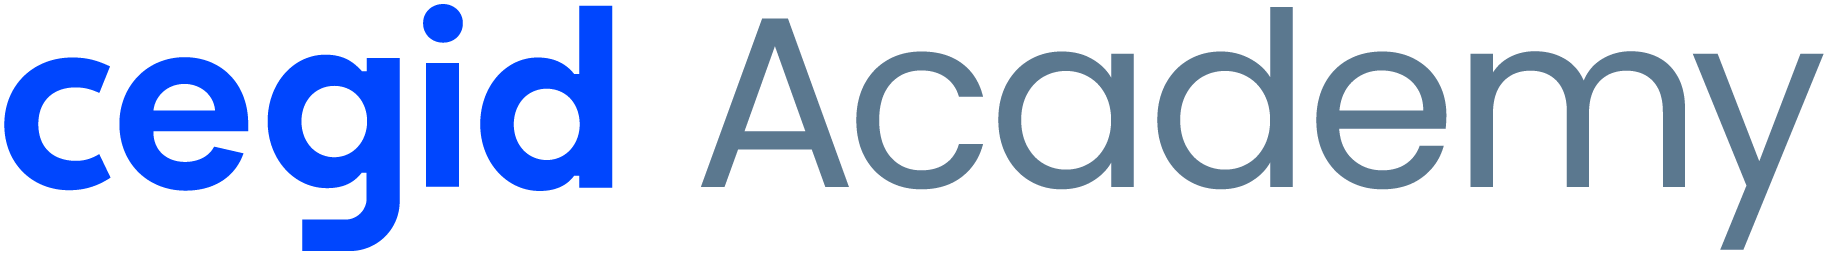<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 6 &middot; Deployment</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Deployment</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M5</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | HR-Job-Change|
| **Grupo** |Grupo 3|
| **Formandos** |Cláudia Candeias - João Abreu |
| **Data** |18/10/2026 |
| **Dataset** |Dados_RH_Mudanca_Emprego.csv |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Colocar o modelo em utilização. Num contexto real pode ser uma API, um dashboard, um relatório ou um sistema automatizado. Neste projeto:<ul style="margin:4px 0 2px 0;"><li>exportar as previsões para ficheiro (entregável <code>&lt;PROJETO&gt;_Results.csv</code>);</li><li>carregar o modelo guardado e prever <b>novos registos</b>;</li><li>(opcional) gravar as previsões numa base de dados;</li><li>definir como o modelo será <b>monitorizado e mantido</b>.</li></ul></div>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>M5 · Comparação final e deployment: escolhe-se o modelo que <b>generaliza melhor</b> (média da CV), guarda-se o <b>pipeline completo</b> com <code>joblib</code>, expõe-se via API/dashboard e <b>monitoriza-se</b> (os dados mudam).</div>

### 0. Configuração
<hr>

**0.1 Bibliotecas** — base, `json`, `pathlib`, `joblib`, `datetime`.

In [5]:
import json
import sqlite3
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from preparacao import preparar  # os mesmos passos da Fase 3

pd.set_option("display.max_columns", None)

**0.2 Configuração** — ler `Data/output/config_projeto.json`.

In [6]:
with open("Data/output/config_projeto.json", encoding="utf-8") as f:
    config = json.load(f)

PROJETO = config["PROJETO"]
TARGET = config["TARGET"]
ID_COLS = config["ID_COLS"]
NUM_COLS = config["NUM_COLS"]
BIN_COLS = config["BIN_COLS"]
CAT_COLS = config["CAT_COLS"]
FEATURES = NUM_COLS + BIN_COLS + CAT_COLS
DATA_PATH = "Data/input/Dados_RH_Mudanca_Emprego.csv"
print(PROJETO, "|", TARGET, "|", len(FEATURES), "features")

HR-Job-Change | procura_mudanca_emprego | 14 features


**0.3 Pastas** — as mesmas dos notebooks anteriores.

In [7]:
for pasta in ["Data/input", "Data/output", "Data/analytics", "Data/models"]:
    Path(pasta).mkdir(parents=True, exist_ok=True)

**0.4 Carregar o modelo**
- `joblib.load` do pipeline final e leitura dos metadados (`.json`).

In [8]:
modelo = joblib.load(f"Data/models/{PROJETO}_modelo_final.joblib")
with open(f"Data/models/{PROJETO}_modelo_final.json", encoding="utf-8") as f:
    info = json.load(f)
with open(f"Data/models/{PROJETO}_prep_params.json", encoding="utf-8") as f:
    prep_params = json.load(f)

LIMIAR = info["limiar_decisao"]  # escolhido na Fase 5 (secção 4.3); se faltar, correr a Fase 5 de novo
print(info["modelo"],"| limiar:", LIMIAR)
modelo

Random Forest (Random) | limiar: 0.55


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['indice_desenvolvimento_cidade','anos_experiencia', 'anos_desde_ultimo_emprego',...,'area_formacao','dimensao_empresa', 'tipo_empresa']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer

### 1. Exportação dos resultados
<hr>

Guardar as previsões num ficheiro para posterior utilização: identificador, valor real, valor previsto e (se existir) probabilidade.

**1.1 [Classificação / Regressão] Exportar as previsões**
- Para o conjunto de teste: identificador, variáveis, valor real, valor previsto e (classificação) probabilidades por classe / (regressão) erro.
- Gravar em `Data/output/<PROJETO>_Results.csv`.

In [9]:
test = pd.read_csv(f"Data/output/{PROJETO}_test.csv", index_col="id_candidato")
X_test, y_test = test[FEATURES], test[TARGET]

resultados = X_test.copy()
resultados["real"] = y_test
resultados["prob_sim"] = modelo.predict_proba(X_test)[:, 1].round(4)
resultados["previsto"] = (resultados["prob_sim"] >= LIMIAR).astype(int)
resultados["previsto_texto"] = resultados["previsto"].map({0: "Não", 1: "Sim"})
resultados["acertou"] = (resultados["real"] == resultados["previsto"]).astype(int)

# ordenado do mais provável para o menos provável: é a lista que os RH vão usar
resultados = resultados.sort_values("prob_sim", ascending=False)
resultados["prioridade"] = range(1, len(resultados) + 1)

resultados.to_csv(f"Data/output/{PROJETO}_Results.csv", encoding="utf-8")
print(resultados.shape)
print(resultados["previsto_texto"].value_counts())
resultados[["prioridade", "prob_sim", "previsto_texto", "real", "acertou"]].head(10)

(3832, 20)
previsto_texto
Não    2604
Sim    1228
Name: count, dtype: int64


,prioridade,prob_sim,previsto_texto,real,acertou
id_candidato,,,,,
181825,1,0.9145,Sim,1,1
166355,2,0.9041,Sim,1,1
403069,3,0.9028,Sim,1,1
181027,4,0.9007,Sim,0,0
650700,5,0.9007,Sim,1,1
918563,6,0.8978,Sim,1,1
878064,7,0.8973,Sim,0,0
331881,8,0.8960,Sim,1,1
966566,9,0.8952,Sim,0,0


##### Análise e Interpretação

> *Os resultados exportados estão completos e prontos a usar por quem vai tomar a decisão?*

**Resposta:**

- Sim. O ficheiro `Data/output/HR-Job-Change_Results.csv` tem os 3 832 candidatos do teste com o `id_candidato` (índice), as 14 variáveis usadas pelo modelo, o valor real, a **probabilidade de procurar mudar** (`prob_sim`), a previsão com o limiar 0,55 (0/1 e "Sim"/"Não"), se acertou, e uma coluna de **prioridade**.
- Está **ordenado da maior para a menor probabilidade**, porque é assim que os RH o vão usar: começam a contactar pelo topo da lista até onde a equipa conseguir. 1 228 candidatos ficam marcados como "Sim".
- O `id_candidato` permite voltar aos dados de contacto do candidato (que não estão no dataset, por privacidade).
- Num uso real, as colunas `real` e `acertou` não existiriam (ainda não se sabe o resultado). Aqui servem para confirmar o desempenho e, no futuro, para comparar com o resultado dos contactos.

<hr>

### 2. Previsão para novos registos
<hr>

O pipeline guardado inclui a imputação, o encoding e o scaling, que são aplicados automaticamente. **Não inclui** o que foi feito fora dele na Fase 3 (limpeza determinística, `criar_features`, capping de outliers, encodings manuais): esses passos têm de ser aplicados aos dados novos **antes** do `predict`, com os mesmos parâmetros aprendidos no treino (`Data/models/<PROJETO>_prep_params.json`).

Se isso não for feito, o modelo recebe dados num formato diferente do que viu no treino (*training-serving skew*) e as previsões ficam erradas — muitas vezes sem qualquer mensagem de erro.

**2.1 Registo de exemplo**
- Mostrar um dicionário com as colunas que o modelo espera (ex.: a primeira linha do teste), para servir de modelo.

In [10]:
# os dados novos chegam no formato do ficheiro original (com cidade e anos em texto)
raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
exemplo_raw = raw.drop(columns=[TARGET]).iloc[0].to_dict()
print("Formato de entrada (como no ficheiro original):")
print(exemplo_raw)

# e é isto que o modelo recebe depois da preparação da Fase 3
print("\nO que o modelo espera:")
X_test.iloc[0].to_dict()

Formato de entrada (como no ficheiro original):
{'id_candidato': 760695, 'cidade': 'Zona_049', 'indice_desenvolvimento_cidade': 0.91, 'genero': nan, 'experiencia_relevante': 'Com experiência relevante', 'inscricao_universidade': 'Não inscrito', 'nivel_educacao': 'Licenciatura', 'area_formacao': 'Ciência, Tecnologia, Engenharia e Matemática', 'anos_experiencia': '6 anos', 'dimensao_empresa': '500 a 999', 'tipo_empresa': 'Empresa privada', 'anos_desde_ultimo_emprego': '1 ano', 'horas_formacao': 21}

O que o modelo espera:


{'indice_desenvolvimento_cidade': 0.897,
 'anos_experiencia': 3.0,
 'anos_desde_ultimo_emprego': 0.0,
 'n_nulos': 0,
 'horas_formacao_log': 3.7612001156935615,
 'empresa_em_falta': 0,
 'nunca_mudou_emprego': 1,
 'nivel_educacao': 'Mestrado',
 'genero': 'Masculino',
 'experiencia_relevante': 'Com experiência relevante',
 'inscricao_universidade': 'Não inscrito',
 'area_formacao': 'Ciência, Tecnologia, Engenharia e Matemática',
 'dimensao_empresa': 'Menos de 10',
 'tipo_empresa': 'Startup em fase inicial'}

**2.2 Prever um novo registo**
- Criar um dicionário com os dados de um caso novo, convertê-lo em DataFrame, aplicar a preparação da Fase 3 que está fora do Pipeline e usar `modelo.predict` (e `predict_proba` em classificação).

In [11]:
# candidato inventado: cidade pouco desenvolvida, pouca experiência, sem dados da empresa
novo = {
    "id_candidato": 999001,
    "cidade": "Zona_065",
    "indice_desenvolvimento_cidade": 0.624,
    "genero": "Masculino",
    "experiencia_relevante": "Sem experiência relevante",
    "inscricao_universidade": "Curso a tempo inteiro",
    "nivel_educacao": "Licenciatura",
    "area_formacao": "Ciência, Tecnologia, Engenharia e Matemática",
    "anos_experiencia": "2 anos",
    "dimensao_empresa": np.nan,
    "tipo_empresa": np.nan,
    "anos_desde_ultimo_emprego": "Nunca",
    "horas_formacao": 40,
}

# teste: número no meio de texto mantém-se e o código 999 passa a nulo, como na Fase 3
t = preparar(pd.DataFrame([{**novo, "anos_experiencia": "5 anos"},
                           {**novo, "anos_experiencia": 7, "horas_formacao": 999}]), prep_params, TARGET)
assert t["anos_experiencia"].tolist() == [5, 7], t["anos_experiencia"].tolist()
assert t["horas_formacao_log"].isna().tolist() == [False, True]

# mudamos uma coisa de cada vez para ver o efeito
cenarios = {
    "original": {},
    "cidade mais desenvolvida (0,92)": {"indice_desenvolvimento_cidade": 0.92},
    "com dados da empresa": {"tipo_empresa": "Empresa privada", "dimensao_empresa": "100 a 500"},
    "15 anos de experiência": {"anos_experiencia": "15 anos"},
    "tudo junto": {"indice_desenvolvimento_cidade": 0.92, "tipo_empresa": "Empresa privada",
                   "dimensao_empresa": "100 a 500", "anos_experiencia": "15 anos"},
}

linhas = []
for nome, mudanca in cenarios.items():
    X_novo = preparar(pd.DataFrame([{**novo, **mudanca}]), prep_params, TARGET)
    prob = modelo.predict_proba(X_novo[FEATURES])[0, 1]
    linhas.append([nome, round(prob, 3), "Sim" if prob >= LIMIAR else "Não"])

pd.DataFrame(linhas, columns=["cenário", "prob_sim", "previsão"])

,cenário,prob_sim,previsão
0,original,0.839,Sim
1,"cidade mais desenvolvida (0,92)",0.853,Sim
2,com dados da empresa,0.770,Sim
3,15 anos de experiência,0.824,Sim
4,tudo junto,0.313,Não


##### Análise e Interpretação

> *A previsão faz sentido para o caso inventado? Testem alterar uma variável importante e vejam o efeito.*

**Resposta:**

- **Faz sentido.** O candidato inventado vive numa cidade pouco desenvolvida (0,624), não tem experiência relevante, só tem 2 anos de experiência, nunca mudou de emprego e não tem dados da empresa. É o perfil que a Fase 2 e a Fase 5 mostraram ter mais procura, e o modelo dá-lhe **0,839 de probabilidade → "Sim"**.
- **Mudando uma variável de cada vez:**
  - **Com dados da empresa** (empresa privada, 100 a 500): desce para 0,770. É a mudança isolada com mais efeito, como esperado pela importância da falta de dados da empresa.
  - **15 anos de experiência:** desce pouco (0,824).
  - **Cidade mais desenvolvida (0,92):** curiosamente, sozinha não baixa a probabilidade (0,853). Numa Random Forest o efeito de uma variável depende das outras: para quem não tem dados da empresa nem experiência relevante, o modelo continua a ver um perfil de procura, seja qual for a cidade.
  - **Tudo junto** (cidade desenvolvida + dados da empresa + 15 anos): cai para **0,313 → "Não"**. É a combinação dos fatores que muda a previsão, não um fator isolado.
- Isto mostra que o modelo capta interações (não é uma soma de efeitos como na regressão logística) e lembra que a interpretação "variável a variável" deve ser feita com cuidado.
- Também confirma que a preparação fora do Pipeline (`preparar()`) funciona com dados no formato original: o texto "2 anos"/"Nunca" é convertido, a `cidade` é removida e as features da Fase 3 são criadas.

<hr>

**2.3 Função de previsão em lote**
- Criar uma função `prever(df_novos)` que aplique a preparação feita fora do Pipeline (mesma função e parâmetros da Fase 3), valide as colunas, devolva as previsões (e a probabilidade) e a data da previsão.

In [12]:
def prever(df_novos):
    X_novos = preparar(df_novos, prep_params, TARGET)
    em_falta = set(FEATURES) - set(X_novos.columns)
    if em_falta:
        raise ValueError(f"Faltam colunas nos dados novos: {em_falta}")

    # o encoder transformaria uma categoria desconhecida (ex.: "masculino") em zeros sem avisar
    prep = modelo.named_steps["prep"]
    for parte in ["ord", "nom"]:
        t = prep.named_transformers_[parte]
        for col, cats in zip(t.feature_names_in_, t.named_steps["encoder"].categories_):
            novos = set(X_novos[col].dropna()) - set(cats)
            if novos:
                raise ValueError(f"{col}: categorias desconhecidas {novos}")

    saida = pd.DataFrame(index=X_novos.index)
    saida["prob_sim"] = modelo.predict_proba(X_novos[FEATURES])[:, 1].round(4)
    saida["previsao"] = np.where(saida["prob_sim"] >= LIMIAR, "Sim", "Não")
    return saida.sort_values("prob_sim", ascending=False)


# teste: os candidatos do teste, lidos do ficheiro ORIGINAL, têm de dar o mesmo que o Results.csv
originais = raw[raw["id_candidato"].isin(X_test.index)]
previsoes = prever(originais)
print(len(previsoes), "candidatos previstos")
print("Mesmas probabilidades que no Results.csv?",
      np.allclose(previsoes["prob_sim"], resultados.loc[previsoes.index, "prob_sim"]))
# teste: uma categoria escrita de outra forma tem de ser rejeitada
try:
    prever(originais.head(1).assign(genero="masculino"))
    raise AssertionError("prever() aceitou uma categoria desconhecida")
except ValueError as e:
    print("Categoria desconhecida rejeitada:", e)

previsoes.head()

3832 candidatos previstos
Mesmas probabilidades que no Results.csv? True
Categoria desconhecida rejeitada: genero: categorias desconhecidas {'masculino'}


,prob_sim,previsao
id_candidato,,
181825,0.9145,Sim
166355,0.9041,Sim
403069,0.9028,Sim
181027,0.9007,Sim
650700,0.9007,Sim


### 3. (Complemento) Gravar previsões numa base de dados
<hr>

Exemplo com SQL Server (`pyodbc`) — não dado em aula. Adaptar o servidor, a base de dados e a tabela.

**3. (Complemento) Base de dados**
- (Opcional) Gravar as previsões numa base de dados (ex.: SQL Server com `pyodbc`).

In [13]:
# usamos SQLite (vem com o Python) em vez de SQL Server, assim não é preciso servidor
caminho_db = Path("Data/output") / f"{PROJETO}_previsoes.db"
con = sqlite3.connect(caminho_db)
resultados.reset_index().to_sql("previsoes", con, if_exists="replace", index=False)

print(pd.read_sql("""
    SELECT previsto_texto, COUNT(*) AS n, ROUND(AVG(prob_sim), 3) AS prob_media, ROUND(AVG(real), 3) AS taxa_sim_real
    FROM previsoes GROUP BY previsto_texto
""", con))
con.close()

  previsto_texto     n  prob_media  taxa_sim_real
0            Não  2604       0.237          0.108
1            Sim  1228       0.776          0.548


### 4. Plano de monitorização e manutenção
<hr>

Um modelo em produção **exige monitorização e manutenção**: os dados mudam ao longo do tempo e o desempenho pode degradar-se.

| Aspeto | Resposta |
|---|---|
| Quem usa o modelo e como (relatório, dashboard, integração num sistema)? | A equipa de RH/recrutamento. Recebe uma lista (CSV/tabela na base de dados) dos candidatos ordenada pela probabilidade de procurarem mudar; pode ser ligada a um dashboard simples. O modelo prioriza, quem decide é o recrutador. |
| Com que frequência são feitas previsões? | Em lote, no fim de cada formação (ou mensalmente) para os novos candidatos, com a função `prever()`. Não é preciso tempo real. |
| Que métrica será acompanhada e qual o limite de alerta? | Recall da classe "Sim" (meta 0,70; **alerta abaixo de 0,65**) e precision (alerta abaixo de 0,45), calculados com o resultado real dos contactos (aceitou/recusou). Também a % de candidatos marcados como "Sim" (hoje ~32%). |
| Os dados de entrada continuam com o mesmo formato e distribuição que os de treino (*data drift*)? Como se verifica? | Formato: `prever()` dá erro se faltarem colunas, e categorias novas são ignoradas pelo `OneHotEncoder`. Distribuição: comparar, em cada lote, a % de valores em falta (sobretudo `tipo_empresa`/`dimensao_empresa`, hoje ~32%), a média do índice da cidade e a proporção de cada categoria com os valores do treino; alerta se a diferença for grande (ex.: mais de 10 p.p.). |
| Quando e como será o modelo retreinado? | Uma vez por ano, ou antes se houver alerta de desempenho ou de drift. Repetem-se as Fases 3 a 5 com os dados novos (incluindo o resultado dos contactos), mantendo a mesma validação cruzada e escolhendo o limiar só no treino. |
| Que riscos existem (dados novos diferentes, variáveis sensíveis, RGPD)? | Mudanças na recolha de dados (ex.: formulário passar a obrigar a empresa) alteram o sinal "Em falta", que é das variáveis mais importantes. `genero` é sensível: o modelo quase não o usa, mas o recall difere entre grupos e deve ser acompanhado (idealmente retirar o género na próxima versão). RGPD: usar só o `id_candidato` (dados pseudonimizados), com acesso restrito à lista e uma base legal para o tratamento; os candidatos devem saber que os dados são usados para recrutamento. |

### 5. Entregáveis do projeto
<hr>

- Notebooks `01` a `06` executados, com todas as secções de **Análise e Interpretação** preenchidas
- Dataset original em `Data/input/`
- Dados preparados em `Data/output/`
- Resultados exportados: `Data/output/<PROJETO>_Results.csv`
- Modelo final em `Data/models/`
- Gráficos principais em `Data/analytics/`
- (Opcional) Relatório final com os principais gráficos e conclusões
- (Sugestão) Repositório no GitHub — serve de portfólio profissional

Entregar numa **pasta zipada** com todos os ficheiros do projeto.

### 6. Síntese da Fase de Deployment
<hr>

Como será utilizado o modelo, que resultados foram exportados e que cuidados de manutenção são necessários?

**Resposta:**

- **Como vai ser usado:** como uma ferramenta de apoio aos RH/recrutamento. Depois de cada formação, os dados dos novos candidatos (no formato do ficheiro original) passam pela função `prever()`, que aplica a preparação da Fase 3, o pipeline guardado e o limiar de 0,55, e devolve uma lista ordenada pela probabilidade de procurarem mudar de emprego. Os recrutadores contactam primeiro os do topo; a decisão final continua a ser deles.
- **Resultados exportados:** `HR-Job-Change_Results.csv` (3 832 candidatos do teste com probabilidade, previsão e prioridade) e a mesma tabela numa base de dados SQLite (`HR-Job-Change_previsoes.db`, tabela `previsoes`). O modelo está em `Data/models/` (pipeline `.joblib` + metadados com o limiar). Foi confirmado que prever a partir dos dados originais dá exatamente as mesmas probabilidades que o ficheiro exportado.
- **Desempenho esperado:** encontrar ~70% dos candidatos recetivos (recall 0,705) e, dos que contactamos, ~55% estarem interessados (contra 25% ao acaso).
- **Manutenção:** acompanhar mensalmente o recall e a precision com o resultado real dos contactos (alerta se o recall descer de 0,65), verificar o *data drift* (sobretudo a % de dados da empresa em falta e o índice da cidade), confirmar que o recall não diverge entre géneros, e retreinar todos os anos ou quando houver alertas, usando as Fases 3 a 5. Os passos fora do pipeline têm de ser sempre os mesmos, guardados em `prep_params.json`.

[← Fase 5: Avaliação](05_evaluation.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>